# 03 — U-Net vs U-Net++ (BUSI)

Réglage sur la **validation uniquement**. Le test n'est jamais chargé ici (il sera évalué une seule fois dans le notebook 04).

- Même encodeur pour les deux modèles : `resnet34` (ImageNet), `in_channels=1`, `classes=1` → seule l'architecture du décodeur change.
- Même prétraitement que Hiba : `lire_image`, `lire_masque`, `redimensionner()` de utils.py, taille 256, images 0-1, miroir aléatoire uniquement sur le train.
- Grille : perte {BCE+Dice, Dice} × lr {1e-3, 1e-4}, arrêt anticipé sur le Dice de validation, seed 42.
- Métriques : `metriques()` de utils.py, image par image, calculées à 256, puis moyenne (rappel : moyenne sans les images normales, où il vaut NaN).

## 1. Imports, seed, chemins

In [2]:
import os, sys, time, copy, random
from pathlib import Path
import numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp

# Se placer à la racine du repo (là où sont utils.py et splits.csv) : les chemins de splits.csv sont relatifs à elle
ROOT = Path.cwd()
while not (ROOT / "utils.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / "utils.py").exists(), "utils.py introuvable : ouvre le notebook depuis le dossier medvision-smart"
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
from utils import charger_split, lire_image, lire_masque, redimensionner, metriques

OUT = ROOT / "outputs"; OUT.mkdir(exist_ok=True)
MOD = ROOT / "models";  MOD.mkdir(exist_ok=True)

SEED = 42
def fixer_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
fixer_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Racine :", ROOT, "| device :", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")

Racine : C:\Users\HP\medvision-smart | device : cuda NVIDIA GeForce RTX 3060 Laptop GPU


## 2. Aperçu de splits.csv (train / val seulement)

In [3]:
df_train, df_val = charger_split("train"), charger_split("val")
print("Colonnes :", list(df_train.columns))
print("train :", len(df_train), "| val :", len(df_val))
COL_IMG  = [c for c in df_train.columns if "image" in c.lower() and "mask" not in c.lower()][0]
COL_MASK = "mask_paths"
COL_CLASSE = [c for c in df_train.columns if c.lower() in ("classe", "class", "label", "categorie", "categorie_img", "type")][0]
CLASSES_VAL = df_val[COL_CLASSE].astype(str).str.lower().values
print("Colonne image :", COL_IMG, "| colonne masques :", COL_MASK, "| colonne classe :", COL_CLASSE)
print("Répartition val :", dict(pd.Series(CLASSES_VAL).value_counts()))
df_train.head(3)

Colonnes : ['id', 'classe', 'split', 'image_path', 'mask_paths', 'nb_masques', 'hauteur', 'largeur', 'ratio_tumeur', 'hash', 'groupe', 'taille_groupe']
train : 537 | val : 114
Colonne image : image_path | colonne masques : mask_paths | colonne classe : classe
Répartition val : {'benign': np.int64(59), 'malignant': np.int64(33), 'normal': np.int64(22)}


,id,classe,split,image_path,mask_paths,nb_masques,hauteur,largeur,ratio_tumeur,hash,groupe,taille_groupe
0,benign (1),benign,train,data/Dataset_BUSI_with_GT/benign/benign (1).png,data/Dataset_BUSI_with_GT/benign/benign (1)_ma...,1,471,562,0.003717,30110d92f6ee8768f3eeb3a3cafbce85,0,2
1,benign (100),benign,train,data/Dataset_BUSI_with_GT/benign/benign (100).png,data/Dataset_BUSI_with_GT/benign/benign (100)_...,2,473,323,0.065526,4d97962935ecb4d50628a7711e177228,2,1
2,benign (101),benign,train,data/Dataset_BUSI_with_GT/benign/benign (101).png,data/Dataset_BUSI_with_GT/benign/benign (101)_...,1,473,563,0.015648,1802770b76fd8105e5c736436fb95001,3,1


## 3. Chargement (même prétraitement que Hiba)

In [4]:
TAILLE_REF = 256   # taille à laquelle on calcule TOUTES les métriques

def charger(split, taille=TAILLE_REF):
    """X (N,H,W) float32 dans [0,1], Y (N,H,W) float32 0/1."""
    assert split in ("train", "val"), "Pas de test dans ce notebook !"
    df = charger_split(split)
    X, Y = [], []
    for _, r in df.iterrows():
        img = lire_image(r[COL_IMG])
        assert img is not None, f"Image introuvable : {r[COL_IMG]} (le dataset est-il bien dans data/ ?)"
        img, m = redimensionner(img, lire_masque(r[COL_MASK]), taille)
        X.append(img); Y.append(m)
    return np.stack(X).astype(np.float32) / 255.0, np.stack(Y).astype(np.float32)

DATA = {}   # cache par taille
def donnees(taille):
    if taille not in DATA:
        DATA[taille] = {s: charger(s, taille) for s in ("train", "val")}
    return DATA[taille]

d256 = donnees(256)
for s, (X, Y) in d256.items():
    print(f"{s:5s} X{X.shape} [{X.min():.2f},{X.max():.2f}]  Y valeurs {np.unique(Y)}  % pixels lésion = {100*Y.mean():.1f}")

train X(537, 256, 256) [0.00,1.00]  Y valeurs [0. 1.]  % pixels lésion = 7.3
val   X(114, 256, 256) [0.00,1.00]  Y valeurs [0. 1.]  % pixels lésion = 7.9


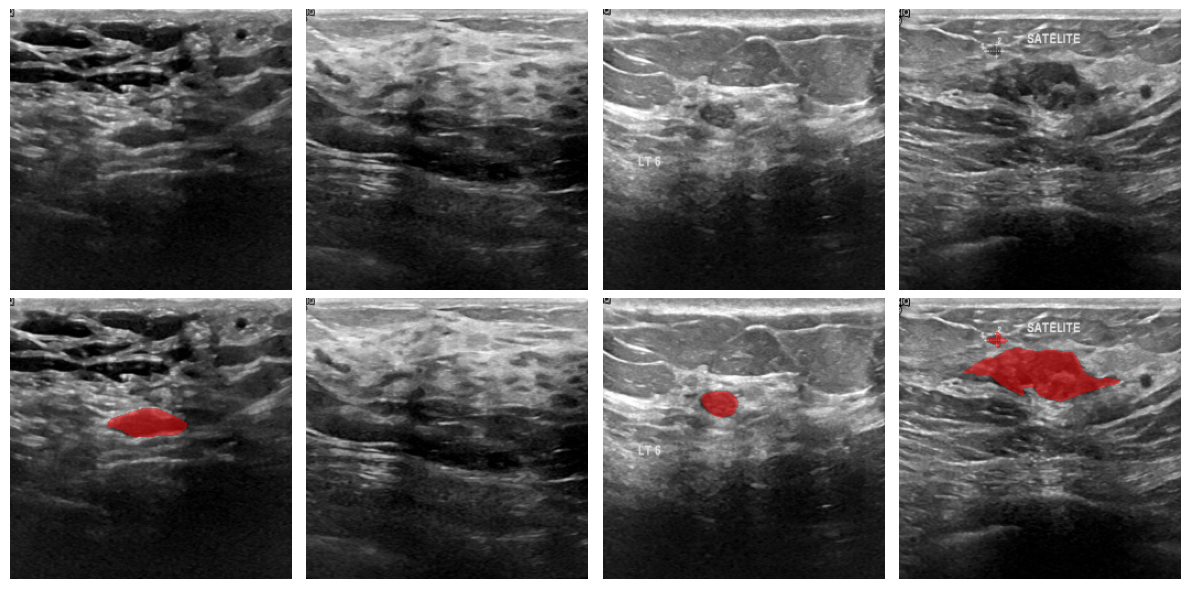

In [5]:
# Contrôle visuel rapide : les masques rouges doivent tomber sur les lésions
X, Y = d256["train"]
fig, ax = plt.subplots(2, 4, figsize=(12, 6))
for k, i in enumerate(np.random.RandomState(0).choice(len(X), 4, replace=False)):
    ax[0, k].imshow(X[i], cmap="gray"); ax[0, k].axis("off")
    ax[1, k].imshow(X[i], cmap="gray"); ax[1, k].imshow(np.ma.masked_where(Y[i] == 0, Y[i]), alpha=.5, cmap="autumn"); ax[1, k].axis("off")
plt.tight_layout(); plt.show()

## 4. Dataset (miroir aléatoire sur le train seulement)

In [6]:
class BUSISeg(Dataset):
    def __init__(self, X, Y, augment=False):
        self.X, self.Y, self.augment = X, Y, augment
    def __len__(self): return len(self.X)
    def __getitem__(self, i):
        x, y = self.X[i], self.Y[i]
        if self.augment and random.random() < 0.5:
            x, y = x[:, ::-1], y[:, ::-1]            # miroir horizontal
        return (torch.from_numpy(np.ascontiguousarray(x))[None],
                torch.from_numpy(np.ascontiguousarray(y))[None])

## 5. Métriques (utils.metriques, image par image à 256)

In [7]:
NOMS = ["dice", "iou", "map", "rappel", "precision"]

def evaluer(probs, Y, seuil=0.5):
    """probs, Y : numpy (N,256,256). Seuil 0.5 puis utils.metriques sur chaque image, puis moyenne.
    nanmean : le rappel vaut NaN sur les images normales (sans tumeur), elles sont exclues de sa moyenne."""
    lignes = [metriques((p > seuil).astype(np.uint8), y.astype(np.uint8)) for p, y in zip(probs, Y)]
    return {k: float(np.nanmean([l[k] for l in lignes])) for k in NOMS}

@torch.no_grad()
def predire(model, X_in, taille_ref=TAILLE_REF, bs=16):
    """Probabilités (N,256,256) numpy, remises à 256 même si le modèle tourne à 128."""
    model.eval(); out = []
    for i in range(0, len(X_in), bs):
        x = torch.from_numpy(X_in[i:i+bs])[:, None].to(device)
        p = torch.sigmoid(model(x))
        if p.shape[-1] != taille_ref:
            p = F.interpolate(p, size=(taille_ref, taille_ref), mode="bilinear", align_corners=False)
        out.append(p[:, 0].cpu().numpy())
    return np.concatenate(out)

@torch.no_grad()
def temps_inference_ms(model, taille, n=50):
    model.eval(); x = torch.rand(1, 1, taille, taille, device=device)
    for _ in range(10): model(x)                     # échauffement GPU
    if device.type == "cuda": torch.cuda.synchronize()
    t = time.perf_counter()
    for _ in range(n): model(x)
    if device.type == "cuda": torch.cuda.synchronize()
    return 1000 * (time.perf_counter() - t) / n

def n_params(model): return sum(p.numel() for p in model.parameters())

## 6. Modèles, pertes, entraînement avec arrêt anticipé

In [8]:
def creer_modele(arch):
    cls = {"unet": smp.Unet, "unetpp": smp.UnetPlusPlus}[arch]
    return cls(encoder_name="resnet34", encoder_weights="imagenet", in_channels=1, classes=1)

dice_loss = smp.losses.DiceLoss(mode="binary", from_logits=True)
bce_loss  = nn.BCEWithLogitsLoss()
PERTES = {
    "bce_dice": lambda lo, y: bce_loss(lo, y) + dice_loss(lo, y),
    "dice":     lambda lo, y: dice_loss(lo, y),
}

def entrainer(arch, perte, lr, taille=256, max_epochs=80, patience=12, bs=8):
    fixer_seed()
    Xtr, Ytr = donnees(taille)["train"]
    Xva_in, Yva_in = donnees(taille)["val"]        # entrée du modèle à la taille choisie (pour la perte val)
    _, Yva_ref = donnees(256)["val"]               # vérité terrain à 256 (pour le Dice)

    g = torch.Generator().manual_seed(SEED)
    dl = DataLoader(BUSISeg(Xtr, Ytr, augment=True), batch_size=bs, shuffle=True,
                    num_workers=0, generator=g)    # num_workers=0 : sûr sous Windows
    model = creer_modele(arch).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    crit = PERTES[perte]

    hist = {"epoch": [], "train_loss": [], "val_loss": [], "val_dice": []}
    best, best_ep, best_state, attente = -1, 0, None, 0
    t0 = time.time()
    for ep in range(1, max_epochs + 1):
        model.train(); tot = 0
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(); l = crit(model(x), y); l.backward(); opt.step()
            tot += l.item() * len(x)
        # --- validation ---
        model.eval(); vl = 0
        with torch.no_grad():
            for i in range(0, len(Xva_in), 16):
                x = torch.from_numpy(Xva_in[i:i+16])[:, None].to(device)
                y = torch.from_numpy(Yva_in[i:i+16])[:, None].to(device)
                vl += crit(model(x), y).item() * len(x)
        vl /= len(Xva_in)
        vd = evaluer(predire(model, Xva_in), Yva_ref)["dice"]   # même Dice que utils.metriques
        hist["epoch"].append(ep); hist["train_loss"].append(tot / len(Xtr))
        hist["val_loss"].append(vl); hist["val_dice"].append(vd)
        print(f"  ep {ep:3d}  train_loss {tot/len(Xtr):.4f}  val_loss {vl:.4f}  val_dice {vd:.4f}")
        if vd > best:
            best, best_ep, attente = vd, ep, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            attente += 1
            if attente >= patience:
                print(f"  arrêt anticipé (meilleure époque {best_ep})"); break
    t_train = time.time() - t0
    model.load_state_dict(best_state)
    return model, hist, best_ep, t_train

def tracer(hist, nom):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(hist["epoch"], hist["train_loss"], label="train"); ax[0].plot(hist["epoch"], hist["val_loss"], label="val")
    ax[0].set_title(f"Perte — {nom}"); ax[0].set_xlabel("époque"); ax[0].legend()
    ax[1].plot(hist["epoch"], hist["val_dice"], color="tab:green"); ax[1].set_title(f"Dice validation — {nom}"); ax[1].set_xlabel("époque")
    plt.tight_layout(); fig.savefig(OUT / f"courbes_{nom}.png", dpi=120); plt.show()

## 7. Test rapide (2 époques) avant la vraie grille

Lance cette cellule d'abord : si elle tourne sans erreur en ~1 minute, tout est prêt. Sinon envoie l'erreur.

In [9]:
_m, _h, _, _t = entrainer("unetpp", "bce_dice", 1e-3, max_epochs=2)
print(f"OK en {_t:.0f} s — {n_params(_m)/1e6:.1f} M paramètres — GPU max utilisé : {torch.cuda.max_memory_allocated()/1e9:.2f} Go")
del _m; torch.cuda.empty_cache()

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

  ep   1  train_loss 0.8281  val_loss 1.1184  val_dice 0.2952
  ep   2  train_loss 0.5891  val_loss 0.6562  val_dice 0.5603
OK en 35 s — 26.1 M paramètres — GPU max utilisé : 2.32 Go


## 8. Grille de réglage : 2 modèles × 2 pertes × 2 lr = 8 configurations


=== unet_bce_dice_lr0.001_256 ===
  ep   1  train_loss 1.0418  val_loss 1.1897  val_dice 0.1075
  ep   2  train_loss 0.6571  val_loss 0.7155  val_dice 0.4304
  ep   3  train_loss 0.6184  val_loss 0.6841  val_dice 0.5192
  ep   4  train_loss 0.5719  val_loss 0.5188  val_dice 0.6255
  ep   5  train_loss 0.4705  val_loss 0.7875  val_dice 0.4788
  ep   6  train_loss 0.5012  val_loss 0.5637  val_dice 0.6051
  ep   7  train_loss 0.4945  val_loss 0.5472  val_dice 0.6020
  ep   8  train_loss 0.4970  val_loss 0.5682  val_dice 0.6053
  ep   9  train_loss 0.4758  val_loss 0.5744  val_dice 0.6436
  ep  10  train_loss 0.4600  val_loss 0.6045  val_dice 0.5978
  ep  11  train_loss 0.4580  val_loss 0.5657  val_dice 0.6116
  ep  12  train_loss 0.4137  val_loss 0.5340  val_dice 0.5839
  ep  13  train_loss 0.4041  val_loss 0.5029  val_dice 0.6109
  ep  14  train_loss 0.3734  val_loss 0.4896  val_dice 0.7013
  ep  15  train_loss 0.4115  val_loss 0.4767  val_dice 0.6522
  ep  16  train_loss 0.4137  val_lo

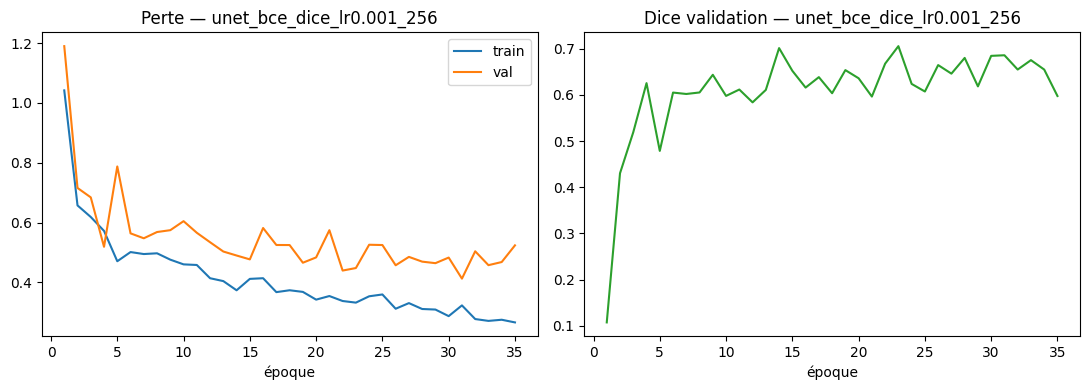


=== unet_bce_dice_lr0.0001_256 ===
  ep   1  train_loss 1.4417  val_loss 1.1486  val_dice 0.3145
  ep   2  train_loss 1.1338  val_loss 0.9450  val_dice 0.4440
  ep   3  train_loss 0.9995  val_loss 0.8813  val_dice 0.6021
  ep   4  train_loss 0.8798  val_loss 0.7577  val_dice 0.6640
  ep   5  train_loss 0.7390  val_loss 0.7166  val_dice 0.6063
  ep   6  train_loss 0.6538  val_loss 0.6681  val_dice 0.6865
  ep   7  train_loss 0.5608  val_loss 0.5655  val_dice 0.5815
  ep   8  train_loss 0.5198  val_loss 0.5704  val_dice 0.6982
  ep   9  train_loss 0.4332  val_loss 0.5045  val_dice 0.6889
  ep  10  train_loss 0.4066  val_loss 0.5178  val_dice 0.7218
  ep  11  train_loss 0.3552  val_loss 0.5363  val_dice 0.6879
  ep  12  train_loss 0.3326  val_loss 0.4080  val_dice 0.6976
  ep  13  train_loss 0.2823  val_loss 0.3553  val_dice 0.7339
  ep  14  train_loss 0.2493  val_loss 0.3952  val_dice 0.7339
  ep  15  train_loss 0.2501  val_loss 0.3956  val_dice 0.7185
  ep  16  train_loss 0.2326  val_l

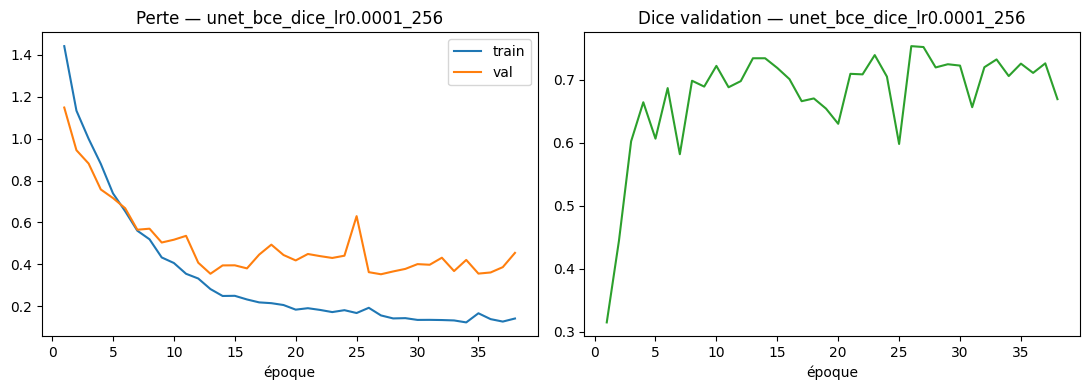


=== unet_dice_lr0.001_256 ===
  ep   1  train_loss 0.7039  val_loss 0.6765  val_dice 0.1471
  ep   2  train_loss 0.4927  val_loss 0.6343  val_dice 0.1881
  ep   3  train_loss 0.4388  val_loss 0.4013  val_dice 0.5629
  ep   4  train_loss 0.3755  val_loss 0.3641  val_dice 0.5533
  ep   5  train_loss 0.3285  val_loss 0.3301  val_dice 0.5323
  ep   6  train_loss 0.3506  val_loss 0.3264  val_dice 0.6048
  ep   7  train_loss 0.3460  val_loss 0.3124  val_dice 0.5660
  ep   8  train_loss 0.3146  val_loss 0.3192  val_dice 0.6070
  ep   9  train_loss 0.3311  val_loss 0.3310  val_dice 0.6004
  ep  10  train_loss 0.3182  val_loss 0.3098  val_dice 0.5789
  ep  11  train_loss 0.2978  val_loss 0.3367  val_dice 0.6159
  ep  12  train_loss 0.2930  val_loss 0.3424  val_dice 0.5742
  ep  13  train_loss 0.2860  val_loss 0.3308  val_dice 0.5387
  ep  14  train_loss 0.3195  val_loss 0.3542  val_dice 0.5987
  ep  15  train_loss 0.3163  val_loss 0.3733  val_dice 0.5611
  ep  16  train_loss 0.2829  val_loss 0

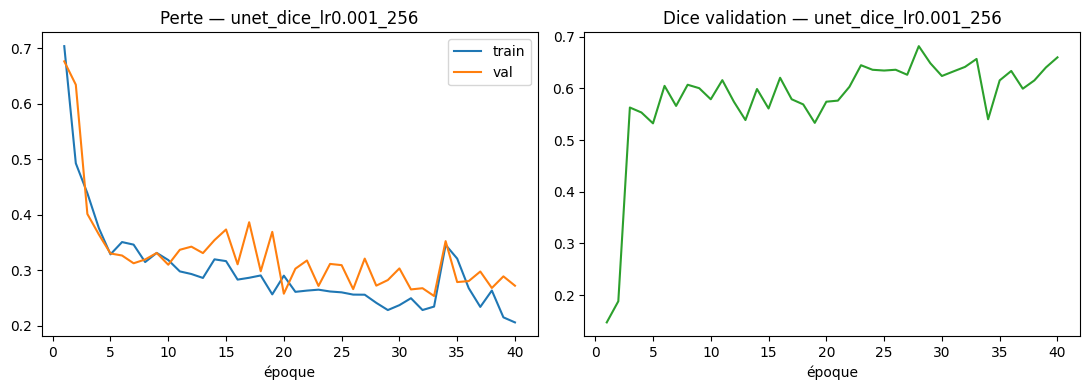


=== unet_dice_lr0.0001_256 ===
  ep   1  train_loss 0.7690  val_loss 0.5694  val_dice 0.4095
  ep   2  train_loss 0.7007  val_loss 0.5430  val_dice 0.4365
  ep   3  train_loss 0.6432  val_loss 0.5172  val_dice 0.5629
  ep   4  train_loss 0.5830  val_loss 0.4832  val_dice 0.5499
  ep   5  train_loss 0.5067  val_loss 0.4176  val_dice 0.6487
  ep   6  train_loss 0.4710  val_loss 0.3978  val_dice 0.6591
  ep   7  train_loss 0.4036  val_loss 0.3932  val_dice 0.6136
  ep   8  train_loss 0.3748  val_loss 0.3486  val_dice 0.6903
  ep   9  train_loss 0.3205  val_loss 0.3372  val_dice 0.7096
  ep  10  train_loss 0.3115  val_loss 0.3476  val_dice 0.7044
  ep  11  train_loss 0.2699  val_loss 0.3240  val_dice 0.6923
  ep  12  train_loss 0.2370  val_loss 0.2989  val_dice 0.6890
  ep  13  train_loss 0.2215  val_loss 0.2749  val_dice 0.6807
  ep  14  train_loss 0.2098  val_loss 0.2824  val_dice 0.6900
  ep  15  train_loss 0.1996  val_loss 0.2586  val_dice 0.6576
  ep  16  train_loss 0.1975  val_loss 

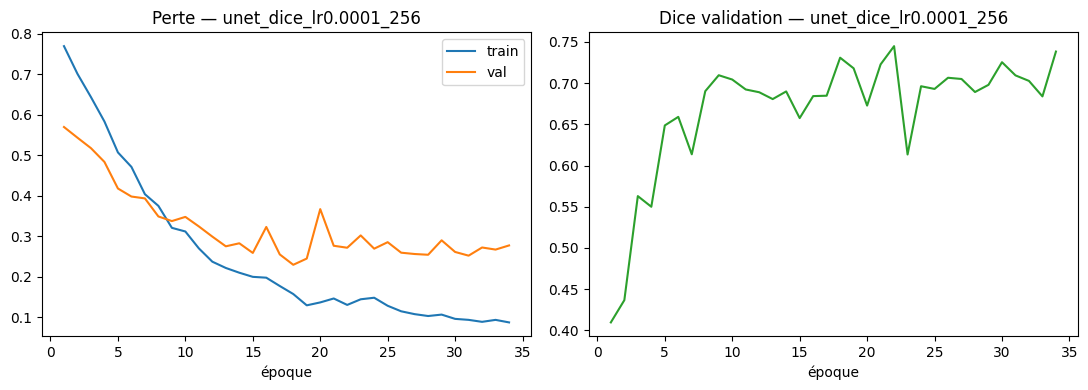


=== unetpp_bce_dice_lr0.001_256 ===
  ep   1  train_loss 0.8281  val_loss 1.1184  val_dice 0.2952
  ep   2  train_loss 0.5891  val_loss 0.6562  val_dice 0.5603
  ep   3  train_loss 0.6128  val_loss 0.6595  val_dice 0.6177
  ep   4  train_loss 0.5466  val_loss 0.5660  val_dice 0.5988
  ep   5  train_loss 0.4545  val_loss 0.5133  val_dice 0.6009
  ep   6  train_loss 0.4781  val_loss 0.5275  val_dice 0.6027
  ep   7  train_loss 0.4874  val_loss 0.5040  val_dice 0.5968
  ep   8  train_loss 0.4465  val_loss 0.5715  val_dice 0.6214
  ep   9  train_loss 0.4634  val_loss 0.5583  val_dice 0.5423
  ep  10  train_loss 0.4378  val_loss 0.5667  val_dice 0.6117
  ep  11  train_loss 0.4412  val_loss 0.5502  val_dice 0.5996
  ep  12  train_loss 0.4127  val_loss 0.5250  val_dice 0.5803
  ep  13  train_loss 0.3682  val_loss 0.5556  val_dice 0.6091
  ep  14  train_loss 0.3825  val_loss 0.5161  val_dice 0.6529
  ep  15  train_loss 0.3699  val_loss 0.4708  val_dice 0.6552
  ep  16  train_loss 0.3950  val_

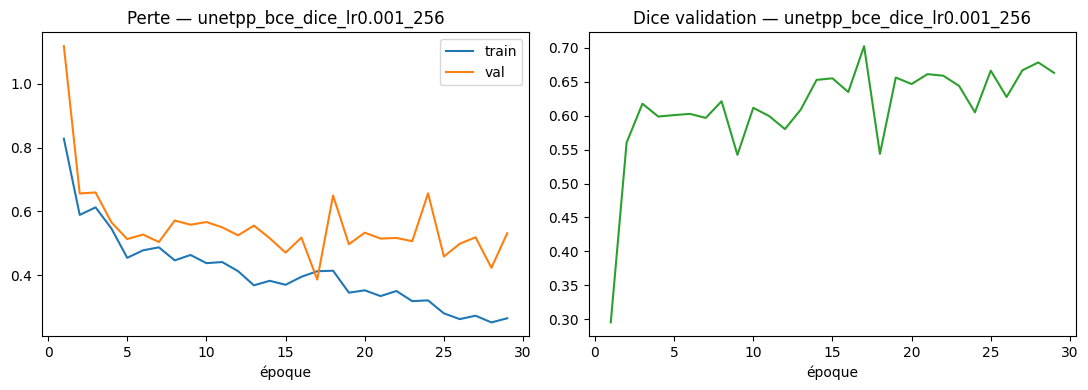


=== unetpp_bce_dice_lr0.0001_256 ===
  ep   1  train_loss 1.1095  val_loss 0.8120  val_dice 0.5621
  ep   2  train_loss 0.8325  val_loss 0.6974  val_dice 0.6207
  ep   3  train_loss 0.6753  val_loss 0.6458  val_dice 0.6645
  ep   4  train_loss 0.5673  val_loss 0.6398  val_dice 0.6563
  ep   5  train_loss 0.4625  val_loss 0.4859  val_dice 0.7146
  ep   6  train_loss 0.4240  val_loss 0.5283  val_dice 0.6432
  ep   7  train_loss 0.3676  val_loss 0.5027  val_dice 0.6958
  ep   8  train_loss 0.3200  val_loss 0.4647  val_dice 0.6989
  ep   9  train_loss 0.2924  val_loss 0.4682  val_dice 0.6367
  ep  10  train_loss 0.2694  val_loss 0.4643  val_dice 0.6958
  ep  11  train_loss 0.2328  val_loss 0.4816  val_dice 0.6828
  ep  12  train_loss 0.2120  val_loss 0.4722  val_dice 0.7033
  ep  13  train_loss 0.1986  val_loss 0.5427  val_dice 0.6609
  ep  14  train_loss 0.1785  val_loss 0.5197  val_dice 0.7012
  ep  15  train_loss 0.1844  val_loss 0.4158  val_dice 0.7372
  ep  16  train_loss 0.1930  val

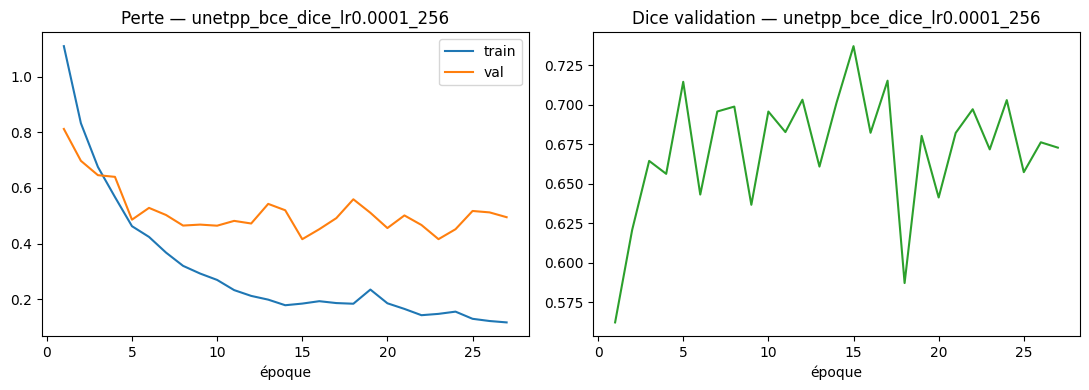


=== unetpp_dice_lr0.001_256 ===
  ep   1  train_loss 0.6032  val_loss 0.6752  val_dice 0.1542
  ep   2  train_loss 0.4267  val_loss 0.5463  val_dice 0.3054
  ep   3  train_loss 0.4036  val_loss 0.4566  val_dice 0.3705
  ep   4  train_loss 0.3895  val_loss 0.4850  val_dice 0.5113
  ep   5  train_loss 0.3431  val_loss 0.3532  val_dice 0.5225
  ep   6  train_loss 0.3622  val_loss 0.3544  val_dice 0.6150
  ep   7  train_loss 0.3286  val_loss 0.2978  val_dice 0.6396
  ep   8  train_loss 0.3004  val_loss 0.3533  val_dice 0.5750
  ep   9  train_loss 0.3380  val_loss 0.3822  val_dice 0.5303
  ep  10  train_loss 0.3200  val_loss 0.2886  val_dice 0.6350
  ep  11  train_loss 0.2848  val_loss 0.3441  val_dice 0.5555
  ep  12  train_loss 0.3053  val_loss 0.2672  val_dice 0.5790
  ep  13  train_loss 0.2734  val_loss 0.2882  val_dice 0.6471
  ep  14  train_loss 0.2764  val_loss 0.3126  val_dice 0.6036
  ep  15  train_loss 0.2790  val_loss 0.3260  val_dice 0.5989
  ep  16  train_loss 0.2825  val_loss

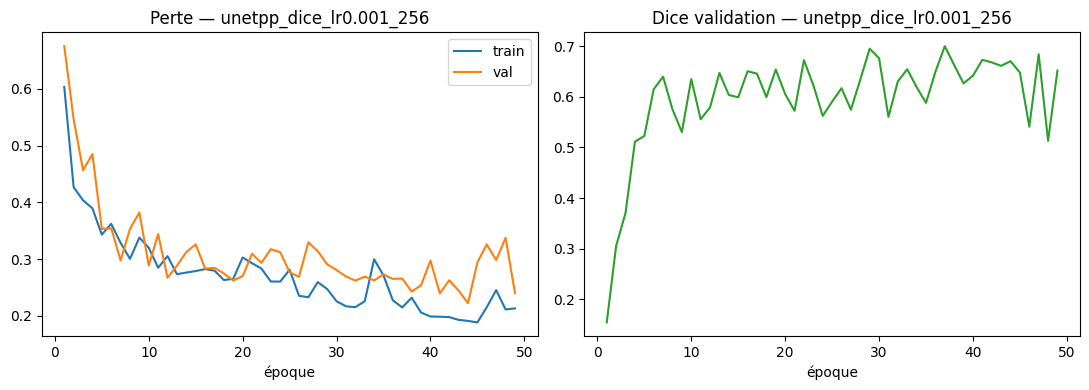


=== unetpp_dice_lr0.0001_256 ===
  ep   1  train_loss 0.7395  val_loss 0.5251  val_dice 0.3923
  ep   2  train_loss 0.6012  val_loss 0.4706  val_dice 0.5441
  ep   3  train_loss 0.4732  val_loss 0.4120  val_dice 0.6054
  ep   4  train_loss 0.3929  val_loss 0.3465  val_dice 0.7004
  ep   5  train_loss 0.3009  val_loss 0.2980  val_dice 0.6329
  ep   6  train_loss 0.2840  val_loss 0.3087  val_dice 0.6924
  ep   7  train_loss 0.2470  val_loss 0.2663  val_dice 0.7281
  ep   8  train_loss 0.2102  val_loss 0.3163  val_dice 0.7042
  ep   9  train_loss 0.2175  val_loss 0.2664  val_dice 0.6458
  ep  10  train_loss 0.2044  val_loss 0.2511  val_dice 0.6878
  ep  11  train_loss 0.1830  val_loss 0.2980  val_dice 0.6298
  ep  12  train_loss 0.1730  val_loss 0.2559  val_dice 0.6579
  ep  13  train_loss 0.1529  val_loss 0.2704  val_dice 0.6827
  ep  14  train_loss 0.1364  val_loss 0.2828  val_dice 0.7228
  ep  15  train_loss 0.1394  val_loss 0.2295  val_dice 0.7022
  ep  16  train_loss 0.1257  val_los

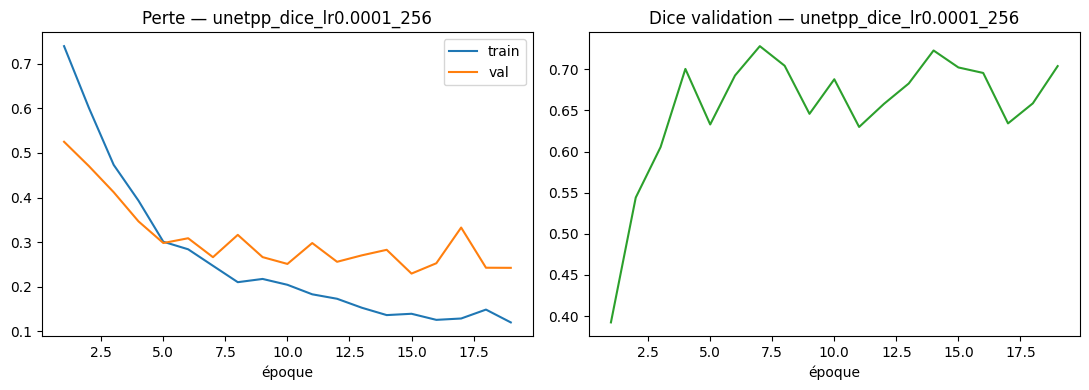

,modele,perte,lr,taille,meilleure_epoque,dice,iou,map,rappel,precision,dice_malignant,temps_entrainement_s,inference_ms_image,n_parametres
0,unet,bce_dice,0.0010,256,23,0.7056,0.6360,0.5088,0.6729,0.7800,0.6435,345.2,12.68,24430097
1,unet,bce_dice,0.0001,256,26,0.7531,0.6766,0.5254,0.7293,0.7960,0.6575,398.9,9.51,24430097
2,unet,dice,0.0010,256,28,0.6817,0.6118,0.4816,0.6338,0.7948,0.5820,369.6,8.18,24430097
3,unet,dice,0.0001,256,22,0.7449,0.6791,0.5544,0.6790,0.7991,0.6384,270.8,7.73,24430097
4,unetpp,bce_dice,0.0010,256,17,0.7026,0.6353,0.5105,0.6760,0.7422,0.6304,475.9,10.85,26072337
5,unetpp,bce_dice,0.0001,256,15,0.7372,0.6691,0.5395,0.7062,0.7934,0.6387,443.6,9.98,26072337
6,unetpp,dice,0.0010,256,37,0.7000,0.6327,0.5000,0.6600,0.7628,0.6055,804.4,10.73,26072337
7,unetpp,dice,0.0001,256,7,0.7281,0.6528,0.5061,0.7023,0.7818,0.6680,308.8,10.21,26072337


In [10]:
RESULTATS, HISTS = [], {}
MEILLEUR = {}   # arch -> (dice, nom, state_dict)

def lancer(arch, perte, lr, taille=256):
    nom = f"{arch}_{perte}_lr{lr:g}_{taille}"
    print(f"\n=== {nom} ===")
    model, hist, best_ep, t_train = entrainer(arch, perte, lr, taille)
    probs = predire(model, donnees(taille)["val"][0]); Yv = donnees(256)["val"][1]
    m = evaluer(probs, Yv)
    mal = np.array(["malig" in c for c in CLASSES_VAL])
    m["dice_malignant"] = evaluer(probs[mal], Yv[mal])["dice"]   # même colonne que le script de Hiba
    ligne = {"modele": arch, "perte": perte, "lr": lr, "taille": taille, "meilleure_epoque": best_ep,
             **{k: round(v, 4) for k, v in m.items()},
             "temps_entrainement_s": round(t_train, 1),
             "inference_ms_image": round(temps_inference_ms(model, taille), 2),
             "n_parametres": n_params(model)}
    RESULTATS.append(ligne); HISTS[nom] = hist
    pd.DataFrame(hist).to_csv(OUT / f"historique_{nom}.csv", index=False)
    tracer(hist, nom)
    if arch not in MEILLEUR or m["dice"] > MEILLEUR[arch][0]:
        MEILLEUR[arch] = (m["dice"], nom, copy.deepcopy(model.state_dict()))
    pd.DataFrame(RESULTATS).to_csv(OUT / "resultats_unet_unetpp_val.csv", index=False)   # sauvegarde au fil de l'eau
    del model; torch.cuda.empty_cache()
    return ligne

for arch in ["unet", "unetpp"]:
    for perte in ["bce_dice", "dice"]:
        for lr in [1e-3, 1e-4]:
            lancer(arch, perte, lr)

pd.DataFrame(RESULTATS)

## 9. Bonus : taille 128 pour la meilleure config de chaque modèle

In [ ]:
FAIRE_BONUS = True
if FAIRE_BONUS:
    df = pd.DataFrame(RESULTATS)
    for arch in ["unet", "unetpp"]:
        b = df[(df.modele == arch) & (df.taille == 256)].sort_values("dice", ascending=False).iloc[0]
        lancer(arch, b.perte, float(b.lr), taille=128)   # prédiction remise à 256 avant les métriques
pd.DataFrame(RESULTATS)

## 10. Sauvegarde des meilleurs poids + tableau final

In [28]:
for arch, fichier in [("unet", "unet_best.pth"), ("unetpp", "unetpp_best.pth")]:
    d, nom, state = MEILLEUR[arch]
    chemin = MOD / fichier
    torch.save(state, chemin)
    taille_mo = chemin.stat().st_size / 1e6
    print(f"{arch:7s} meilleure config = {nom}  (Dice val {d:.4f})  -> {chemin.name}  {taille_mo:.1f} Mo")
    if taille_mo > 95:   # GitHub refuse > 100 Mo : version float16 (≈ moitié), à recharger avec .float()
        c16 = MOD / fichier.replace(".pth", "_fp16.pth")
        torch.save({k: v.half() for k, v in state.items()}, c16)
        print(f"         + version fp16 : {c16.name}  {c16.stat().st_size/1e6:.1f} Mo")

res = pd.DataFrame(RESULTATS)
res.to_csv(OUT / "resultats_unet_unetpp_val.csv", index=False)
res.sort_values("dice", ascending=False)

unet    meilleure config = unet_bce_dice_lr0.0001_256  (Dice val 0.7531)  -> unet_best.pth  97.9 Mo
         + version fp16 : unet_best_fp16.pth  49.0 Mo
unetpp  meilleure config = unetpp_bce_dice_lr0.0001_256  (Dice val 0.7372)  -> unetpp_best.pth  104.5 Mo
         + version fp16 : unetpp_best_fp16.pth  52.3 Mo


,modele,perte,lr,taille,meilleure_epoque,dice,iou,map,rappel,precision,dice_malignant,temps_entrainement_s,inference_ms_image,n_parametres
1,unet,bce_dice,0.0001,256,26,0.7531,0.6766,0.5254,0.7293,0.7960,0.6575,398.9,9.51,24430097
3,unet,dice,0.0001,256,22,0.7449,0.6791,0.5544,0.6790,0.7991,0.6384,270.8,7.73,24430097
5,unetpp,bce_dice,0.0001,256,15,0.7372,0.6691,0.5395,0.7062,0.7934,0.6387,443.6,9.98,26072337
7,unetpp,dice,0.0001,256,7,0.7281,0.6528,0.5061,0.7023,0.7818,0.6680,308.8,10.21,26072337
9,unetpp,bce_dice,0.0001,128,16,0.7231,0.6544,0.5202,0.6652,0.7718,0.6348,144.9,12.22,26072337
23,unetpp,bce_dice,0.0001,128,16,0.7231,0.6544,0.5202,0.6652,0.7718,0.6348,134.8,9.77,26072337
15,unetpp,bce_dice,0.0001,128,16,0.7231,0.6544,0.5202,0.6652,0.7718,0.6348,137.9,10.32,26072337
17,unetpp,bce_dice,0.0001,128,16,0.7231,0.6544,0.5202,0.6652,0.7718,0.6348,136.0,10.44,26072337
13,unetpp,bce_dice,0.0001,128,16,0.7231,0.6544,0.5202,0.6652,0.7718,0.6348,142.8,12.15,26072337
11,unetpp,bce_dice,0.0001,128,16,0.7231,0.6544,0.5202,0.6652,0.7718,0.6348,139.7,11.14,26072337


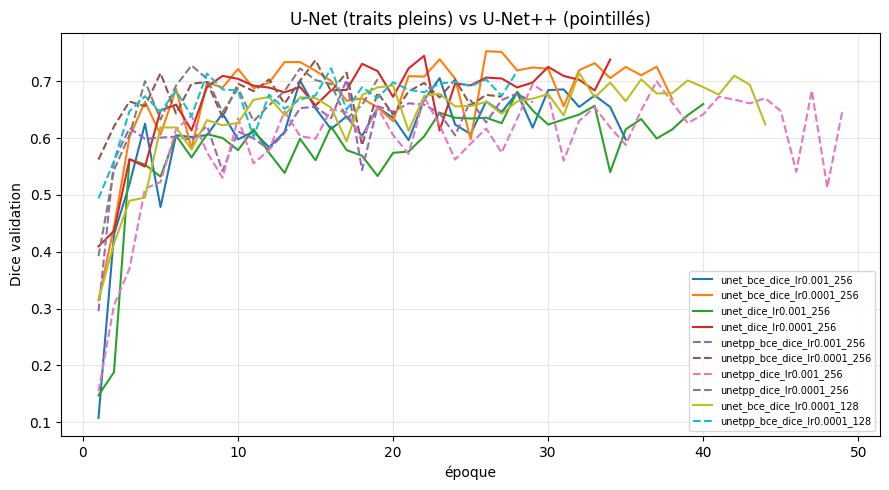

In [30]:
# Comparaison des courbes de Dice de validation
plt.figure(figsize=(9, 5))
for nom, h in HISTS.items():
    plt.plot(h["epoch"], h["val_dice"], label=nom, ls="-" if nom.startswith("unet_") else "--")
plt.xlabel("époque"); plt.ylabel("Dice validation"); plt.legend(fontsize=7); plt.grid(alpha=.3)
plt.title("U-Net (traits pleins) vs U-Net++ (pointillés)")
plt.tight_layout(); plt.savefig(OUT / "comparaison_dice_val.png", dpi=120); plt.show()